# Predicting Airborne Time

Compare distance-only OLS with multiple OLS, Ridge, Lasso, and Elastic Net using **distance, scheduled elapsed time, airline, and month**.

We use a **0.05% sample**, **seed 42**, and an **80/20 train/test split**. The outcome is `air_time`, measured in minutes.

## 1. Setup

Run this notebook from the DX799 folder.

In [1]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 0.0005  # 0.05%
DATA_PATH = "datasets/USDOT_1987_2025_Flights_Dataset/flights_2008_2025_cleaned.parquet"

## 2. Sample the data

Select random rows without replacement. Reading one Parquet row group at a time avoids loading all 114 million rows into memory. The seed reproduces the same sample from the same file.

In [2]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group)
        parts.append(table.take(rows).to_pandas())
    offset = end
data = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(data):,} flights")

Sample: 57,181 flights


## 3. Keep eligible flights

Use completed, nondiverted flights with valid predictors and airborne time. Scheduled elapsed time includes planned taxi time; airborne time excludes it.

In [3]:
sample = data.loc[(data["cancelled"] == 0) & (data["diverted"] == 0)].copy()
numeric = ["distance", "scheduled_elapsed_time"]
print(f"Eligible: {len(sample):,}; excluded: {len(data) - len(sample):,}")
sample[numeric].describe().round(2)

Eligible: 55,980; excluded: 1,201


,distance,scheduled_elapsed_time
count,55980.00,55980.00
mean,796.03,139.33
std,592.28,72.72
min,31.00,21.00
25%,363.00,86.00
50%,632.00,120.00
75%,1028.00,170.00
max,4983.00,680.00


In [4]:
def hhmm_to_minutes(series):
    # Convert values to strings and remove colons
    times = (
        series.astype("string")
        .str.strip()
        .str.replace(":", "", regex=False)
    )

    # Convert HHMM strings into numbers
    times = pd.to_numeric(times, errors="coerce")

    # Extract hours and minutes
    hours = times // 100
    minutes = times % 100

    # Check for valid time values
    valid = (
        hours.between(0, 23)
        & minutes.between(0, 59)
    )

    # Convert to minutes since midnight
    total_minutes = hours * 60 + minutes

    return total_minutes.where(valid)

In [5]:
sample['scheduled_arrival_minutes'] = hhmm_to_minutes(sample['scheduled_arrival_hhmm'])
sample['crs_dep_time_minutes'] = hhmm_to_minutes(sample['crs_dep_time_hhmm'])
sample.drop('crs_dep_time_hhmm', axis=1, inplace=True)
sample.drop('scheduled_arrival_hhmm', axis=1, inplace=True)

In [6]:
airport_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airports.csv')
airport_df = airport_df[['airport_id', 'airport_code']]

airport_dict = (
    airport_df
    .set_index("airport_id")["airport_code"]
    .to_dict()
)
sample['origin_airport'] = sample['origin_airport_id'].map(airport_dict)
sample['dest_airport'] = sample['dest_airport_id'].map(airport_dict)
sample.drop('dest_airport_id', axis=1, inplace=True)
sample.drop('origin_airport_id', axis=1, inplace=True)



In [7]:
airline_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airlines.csv')
airline_df = airline_df[['IATA_CODE_Reporting_Airline', 'airline_name']]

airline_dict = (
    airline_df
    .set_index("IATA_CODE_Reporting_Airline")["airline_name"]
    .to_dict()
)

sample['airline_name'] = sample['airline'].map(airline_dict)
sample['airline_name'] = sample['airline_name'].str.title()

We now drop the remaining columns not being used

In [8]:
features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'distance', 
    'dest_airport', 
    'crs_dep_time_minutes', 
    'scheduled_elapsed_time', 
    'scheduled_arrival_minutes',
]


target = "arrival_delay"

model_data = sample[features + [target]].copy()


In [9]:
top_20_origins = (
    model_data["origin_airport"]
    .value_counts()
    .head(20)
    .index
)

model_data = model_data.loc[
    model_data["origin_airport"].isin(top_20_origins)
]

In [10]:
top_20_dest = (
    model_data["dest_airport"]
    .value_counts()
    .head(20)
    .index
)


model_data["dest_airport_group"] = np.where(
    model_data["dest_airport"].isin(top_20_dest),
    model_data["dest_airport"],
    "Other"
)

In [11]:
features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'distance', 
    'dest_airport', 
    'crs_dep_time_minutes', 
    'scheduled_elapsed_time', 
    'scheduled_arrival_minutes',
    'dest_airport_group']

In [12]:
model_data[features]

,month,year,dayofweek,airline,origin_airport,distance,dest_airport,crs_dep_time_minutes,scheduled_elapsed_time,scheduled_arrival_minutes,dest_airport_group
1,7,2008,6,9E,ATL,692.0,MCI,1305,131.0,1376,Other
2,7,2008,3,9E,MSP,284.0,GFK,885,70.0,955,Other
4,7,2008,6,9E,DTW,300.0,SCE,1293,85.0,1378,Other
5,7,2008,4,9E,DTW,166.0,DAY,1291,59.0,1350,Other
14,7,2008,1,AA,EWR,2454.0,LAX,555,360.0,735,LAX
...,...,...,...,...,...,...,...,...,...,...,...
57168,2,2025,6,AA,LAS,236.0,LAX,1175,80.0,1255,LAX
57170,2,2025,6,AA,ORD,599.0,CLT,492,123.0,675,CLT
57171,2,2025,1,AA,CLT,1773.0,PHX,575,294.0,749,PHX
57172,2,2025,6,AA,LAX,1235.0,DFW,1174,181.0,35,DFW


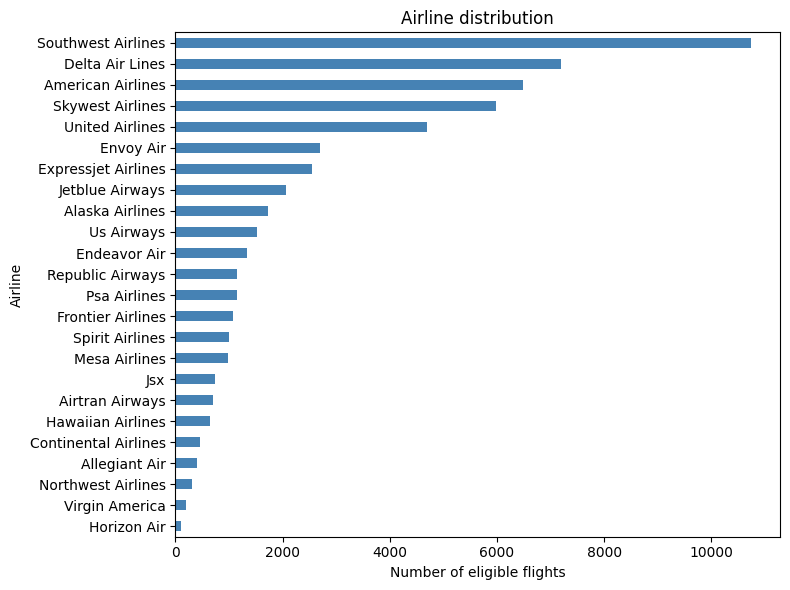

In [13]:
airlines = sample["airline_name"].value_counts().sort_values()
airlines.plot.barh(figsize=(8, 6), color="steelblue")
plt.title("Airline distribution")
plt.xlabel("Number of eligible flights")
plt.ylabel("Airline")
plt.tight_layout()
plt.show()

## 4. Train/test split

All models use the same split. Preprocessing and tuning use training data only.

Training: 23,692; testing: 5,923


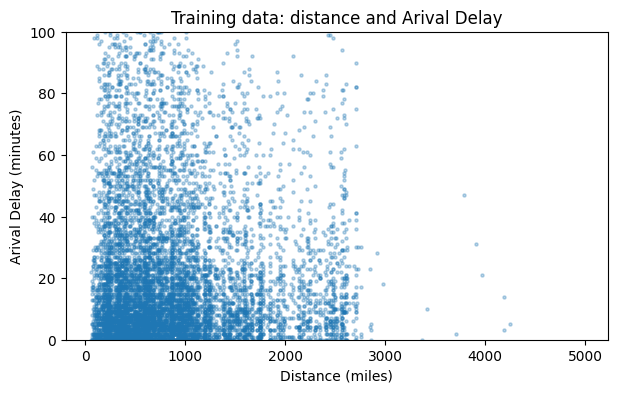

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
   model_data[features], model_data['arrival_delay'], test_size=0.2, random_state=SEED
)
print(f"Training: {len(X_train):,}; testing: {len(X_test):,}")

plt.figure(figsize=(7, 4))
plt.scatter(X_train["distance"], y_train, s=5, alpha=0.3)
plt.xlabel("Distance (miles)")
plt.ylabel("Arival Delay (minutes)")
plt.title("Training data: distance and Arival Delay")
plt.ylim([0,100])
plt.show()

## 5. Fit the models

- **OLS:** Fits coefficients without a penalty.
- **Ridge:** Shrinks coefficients using an L2 penalty.
- **Lasso:** Uses an L1 penalty and can set coefficients to zero.
- **Elastic Net:** Combines L1 and L2 penalties.

One-hot encode airline and month, dropping one reference category each. Standardize all encoded columns inside each training fold. Five-fold cross-validation selects penalties by lowest RMSE; larger `alpha` means a stronger penalty within a method. The simple OLS model uses distance only.

In [15]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport_group', ]

In [16]:
X_train.columns

Index(['month', 'year', 'dayofweek', 'airline', 'origin_airport', 'distance',
       'dest_airport', 'crs_dep_time_minutes', 'scheduled_elapsed_time',
       'scheduled_arrival_minutes', 'dest_airport_group'],
      dtype='str')

In [18]:
simple_features = ColumnTransformer([("distance", "passthrough", ["distance"])])
all_features = ColumnTransformer([
    ("numeric", "passthrough", numerical_features),
    ("categories", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical_features),
])

settings = {
    "Simple OLS": (simple_features, LinearRegression(), {}),
    "Multiple OLS": (all_features, LinearRegression(), {}),
    "Ridge": (all_features, Ridge(), {"model__alpha": np.logspace(-4, 4, 17)}),
    "Lasso": (all_features, Lasso(max_iter=10000, tol=1e-7), {"model__alpha": np.logspace(-4, 2, 13)}),
    "Elastic Net": (all_features, ElasticNet(max_iter=10000, tol=1e-7), {
        "model__alpha": np.logspace(-4, 2, 13), "model__l1_ratio": [0.1, 0.5, 0.9]}),
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
models, tuning = {}, []

with threadpool_limits(limits=1):  # Avoid excess CPU threads during the search.
    for name, (preprocessor, estimator, grid) in settings.items():
        pipeline = Pipeline([("features", preprocessor), ("scale", StandardScaler()), ("model", estimator)])
        search = GridSearchCV(pipeline, grid, cv=cv, scoring="neg_root_mean_squared_error")
        search.fit(X_train, y_train)
        models[name] = search.best_estimator_
        tuning.append({"Model": name, "CV RMSE": -search.best_score_, "Parameters": search.best_params_})
pd.DataFrame(tuning).set_index("Model").round(4)

,CV RMSE,Parameters
Model,,
Simple OLS,42.9850,{}
Multiple OLS,42.4880,{}
Ridge,42.4879,{'model__alpha': 10.0}
Lasso,42.4877,{'model__alpha': 0.0031622776601683794}
Elastic Net,42.4877,"{'model__alpha': 0.0031622776601683794, 'model..."


In [19]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV, KFold
from threadpoolctl import threadpool_limits

import numpy as np
import pandas as pd

settings = {
    "Simple OLS": (
        simple_features,
        LinearRegression(),
        {}
    ),

    "Multiple OLS": (
        all_features,
        LinearRegression(),
        {}
    ),

    "Ridge": (
        all_features,
        Ridge(),
        {"model__alpha": np.logspace(-4, 4, 17)}
    ),

    "Lasso": (
        all_features,
        Lasso(max_iter=10000, tol=1e-5),
        {"model__alpha": np.logspace(-4, 2, 13)}
    ),

    "Elastic Net": (
        all_features,
        ElasticNet(max_iter=10000, tol=1e-5),
        {
            "model__alpha": np.logspace(-4, 2, 13),
            "model__l1_ratio": [0.1, 0.5, 0.9]
        }
    )
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

models = {}
tuning = []

with threadpool_limits(limits=1):

    for name, (preprocessor, estimator, grid) in settings.items():

        pipeline = Pipeline([
            ("features", preprocessor),
            ("model", estimator)
        ])

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=grid,
            cv=cv,
            scoring="neg_root_mean_squared_error",
            n_jobs=-1
        )

        search.fit(X_train, y_train)

        models[name] = search.best_estimator_

        tuning.append({
            "Model": name,
            "CV RMSE": -search.best_score_,
            "Parameters": search.best_params_
        })

results = pd.DataFrame(tuning).set_index("Model")

display(results.round(4))


,CV RMSE,Parameters
Model,,
Simple OLS,42.9850,{}
Multiple OLS,42.4880,{}
Ridge,42.4685,{'model__alpha': 316.22776601683796}
Lasso,42.4838,{'model__alpha': 0.03162277660168379}
Elastic Net,42.4683,"{'model__alpha': 0.01, 'model__l1_ratio': 0.1}"


## 6. Compare test results

**MAE** is average absolute error. **RMSE** gives larger errors more weight. Both are in minutes; lower is better. **R²** measures fit, with 1 representing perfect predictions.

In [ ]:
predictions, scores = {}, []
for name, model in models.items():
    prediction = model.predict(X_test)
    predictions[name] = prediction
    coefficients = model.named_steps["model"].coef_
    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, prediction),
        "RMSE": root_mean_squared_error(y_test, prediction),
        "R²": r2_score(y_test, prediction),
        "Predictors": len(coefficients),
        "Zero coefficients": int((coefficients == 0).sum()),
    })
results = pd.DataFrame(scores).set_index("Model")
results.round(4)

,MAE,RMSE,R²,Predictors,Zero coefficients
Model,,,,,
Simple OLS,22.0808,38.0529,0.0003,1,0
Multiple OLS,21.8699,37.6192,0.0230,100,0
Ridge,21.8233,37.5784,0.0251,100,0
Lasso,21.8636,37.5979,0.0241,100,1
Elastic Net,21.8288,37.5752,0.0253,100,3


### Regression coefficients

Coefficients are converted back to original units. Airline effects are relative to **9E**, and month effects to **January**, holding other inputs fixed. A dash means the predictor was not included; it is different from a zero coefficient.

In [ ]:
pd.set_option("display.max_rows", 90)
lasso_model = models["Lasso"]

feature_names = (
    lasso_model.named_steps["features"]
    .get_feature_names_out()
)

coefs = lasso_model.named_steps["model"].coef_

lasso_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefs
})

selected = lasso_coefficients[
    ~np.isclose(lasso_coefficients["Coefficient"], 0, atol=1e-8)
]

display(selected[:].sort_values("Coefficient"))

,Feature,Coefficient
26,categories__year_2020.0,-14.528931
71,categories__origin_airport_LAX,-5.729055
11,categories__month_9.0,-5.081643
76,categories__origin_airport_PHX,-5.013637
16,categories__year_2010.0,-4.871024
...,...,...
41,categories__airline_CO,8.191983
44,categories__airline_F9,8.849646
40,categories__airline_B6,8.913006
51,categories__airline_OH,10.271144


In [ ]:
feature_groups = [
    "distance",
    "crs_dep_time_minutes",
    "scheduled_elapsed_time",
    "scheduled_arrival_minutes",
    "month",
    "year",
    "dayofweek",
    "airline",
    "origin_airport",
    "dest_airport_group"
]

summary = []

for feature in feature_groups:

    if feature in numerical_features:
        mask = lasso_coefficients["Feature"].eq(f"numeric__{feature}")
    else:
        mask = lasso_coefficients["Feature"].str.startswith(
            f"categories__{feature}_"
        )

    group = lasso_coefficients.loc[mask]

    summary.append({
        "Feature": feature,
        "Total Coefficients": len(group),
        "Retained": np.count_nonzero(
            ~np.isclose(group["Coefficient"], 0, atol=1e-8)
        ),
        "Eliminated": np.count_nonzero(
            np.isclose(group["Coefficient"], 0, atol=1e-8)
        )
    })

display(pd.DataFrame(summary))

,Feature,Total Coefficients,Retained,Eliminated
0,distance,1,1,0
1,crs_dep_time_minutes,1,1,0
2,scheduled_elapsed_time,1,1,0
3,scheduled_arrival_minutes,1,1,0
4,month,11,11,0
5,year,17,17,0
6,dayofweek,6,6,0
7,airline,23,23,0
8,origin_airport,19,19,0
9,dest_airport_group,20,19,1


In [ ]:
import numpy as np
import pandas as pd

coefficient_columns = {}

for name, pipeline in models.items():

    preprocessor = pipeline.named_steps["features"]
    regression = pipeline.named_steps["model"]

    # Get encoded feature names
    names = [
        col.split("__", 1)[1]
        for col in preprocessor.get_feature_names_out()
    ]

    # Obtain fitted coefficients
    values = regression.coef_.copy()

    # Recover original units for scaled numerical features
    scales = np.ones(len(values))
    means = np.zeros(len(values))

    for transformer_name, transformer, columns in preprocessor.transformers_:

        if transformer_name == "remainder":
            continue

        if isinstance(transformer, StandardScaler):

            indices = preprocessor.output_indices_[transformer_name]

            scales[indices] = transformer.scale_
            means[indices] = transformer.mean_

    # Convert coefficients back to original units
    original_values = values / scales

    # Adjust intercept
    intercept = (
        regression.intercept_
        - np.dot(original_values, means)
    )

    coefficient_columns[name] = pd.Series(
        [intercept, *original_values],
        index=["Intercept", *names]
    )

coefficients = pd.DataFrame(coefficient_columns)

display(
    coefficients.style.format(
        precision=5,
        na_rep="—"
    )
)

,Simple OLS,Multiple OLS,Ridge,Lasso,Elastic Net
Intercept,6.21859,1.20411,1.42652,3.04105,2.10109
airline_AA,—,9.48686,1.65034,5.79819,1.76308
airline_AS,—,4.51734,-2.53907,0.53824,-2.68760
airline_B6,—,12.45256,3.95777,8.91301,4.33761
airline_CO,—,11.88446,2.43266,8.19198,2.86521
airline_DL,—,4.10890,-2.86492,0.67307,-2.82014
airline_EV,—,9.64082,2.00109,6.16587,2.21209
airline_F9,—,12.70737,2.88890,8.84965,3.37245
airline_FL,—,8.77998,1.17065,5.31112,1.36805
airline_G4,—,7.49143,-0.05483,2.01412,-0.00000


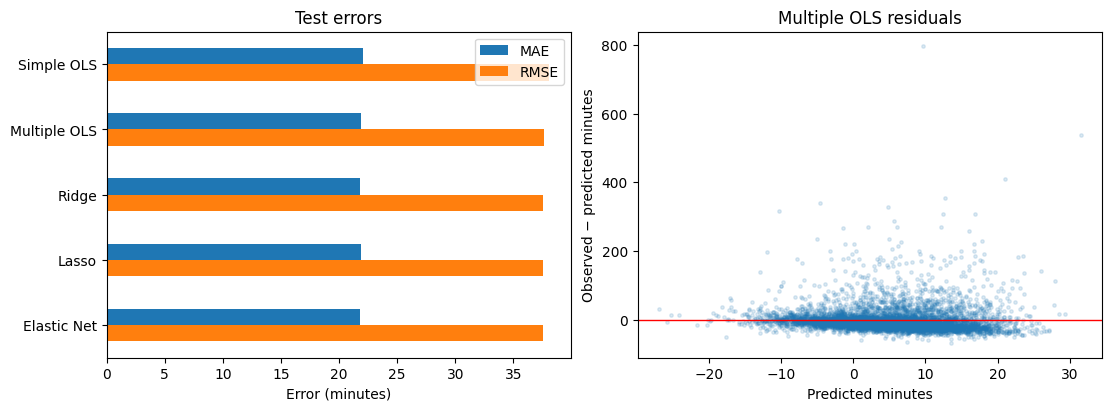

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
results[["MAE", "RMSE"]].plot.barh(ax=axes[0])
axes[0].invert_yaxis()
axes[0].set(title="Test errors", xlabel="Error (minutes)", ylabel="")

prediction = predictions["Multiple OLS"]
axes[1].scatter(prediction, y_test - prediction, s=6, alpha=0.15)
axes[1].axhline(0, color="red", linewidth=1)
axes[1].set(title="Multiple OLS residuals", xlabel="Predicted minutes", ylabel="Observed − predicted minutes")
plt.show()

## 7. Findings

The comparison of test errors indicates that Ridge, Lasso, and Elastic Net provide modest improvements over ordinary least squares regression, although the differences between the regularized models are minimal. The residual plot reveals a pronounced positive tail, with several flights experiencing substantially greater delays than predicted. Predictions are concentrated within a relatively narrow range, suggesting that the model captures modest variations in typical arrival delays but struggles with extreme delays. The low R² values further indicate that the available predictors explain only a small portion of the overall variation in arrival delays.
The most important takeaway: Our primary limitation appears to be the predictive information contained in the available features, rather than simply the choice between OLS, Ridge, Lasso, and Elastic Net.